In [2]:
pip install scikit-learn

In [3]:
pip install numpy

In [4]:

pip install pandas

In [5]:
pip install nltk

In [6]:
pip install matplotlib

In [7]:
pip install imblearn

In [8]:
pip install spacy

In [9]:
pip install keras

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.feature_extraction.text import TfidfTransformer, CountVectorizer, TfidfVectorizer
from sklearn.metrics import confusion_matrix, classification_report, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split

from nltk.stem.porter import PorterStemmer
import nltk
import re, string
from nltk.corpus import stopwords

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

from sklearn.model_selection import cross_val_score

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import classification_report
from sklearn import metrics
import keras

In [11]:
url = "https://drive.google.com/uc?export=download&id=12fBlhsa5GIdtme1jT3KlPPIgIdjzqhv1"
df = pd.read_json(url, lines=True, orient='columns')
print(df.head())

                                             content  \
0                             Get fucking real dude.   
1   She is as dirty as they come  and that crook ...   
2   why did you fuck it up. I could do it all day...   
3   Dude they dont finish enclosing the fucking s...   
4   WTF are you talking about Men? No men thats n...   

                      annotation  extras  
0  {'notes': '', 'label': ['1']}     NaN  
1  {'notes': '', 'label': ['1']}     NaN  
2  {'notes': '', 'label': ['1']}     NaN  
3  {'notes': '', 'label': ['1']}     NaN  
4  {'notes': '', 'label': ['1']}     NaN  


In [12]:
import ast

# Ensure annotation column contains dictionaries, not strings
df["annotation"] = df["annotation"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Use a proper loop without modifying the original column while iterating
for i in range(len(df)):
    if isinstance(df.annotation[i], dict) and "label" in df.annotation[i]:
        df.at[i, "annotation"] = 1 if df.annotation[i]["label"][0] == "1" else 0

# Rename column for clarity
df.rename(columns={"annotation": "label"}, inplace=True)

# Display first few rows
print(df.head())


                                             content label  extras
0                             Get fucking real dude.     1     NaN
1   She is as dirty as they come  and that crook ...     1     NaN
2   why did you fuck it up. I could do it all day...     1     NaN
3   Dude they dont finish enclosing the fucking s...     1     NaN
4   WTF are you talking about Men? No men thats n...     1     NaN


In [13]:
df.drop(['extras'],axis = 1,inplace = True)
df

,content,label
0,Get fucking real dude.,1
1,She is as dirty as they come and that crook ...,1
2,why did you fuck it up. I could do it all day...,1
3,Dude they dont finish enclosing the fucking s...,1
4,WTF are you talking about Men? No men thats n...,1
...,...,...
19996,I dont. But what is complaining about it goi...,0
19997,Bahah yeah i&;m totally just gonna&; get pis...,0
19998,hahahahaha >:) im evil mwahahahahahahahahaha,0
19999,What&;s something unique about Ohio? :),0


In [14]:
df.shape

(20001, 2)

In [15]:
df.rename(columns={"label": "annotation"}, inplace=True)

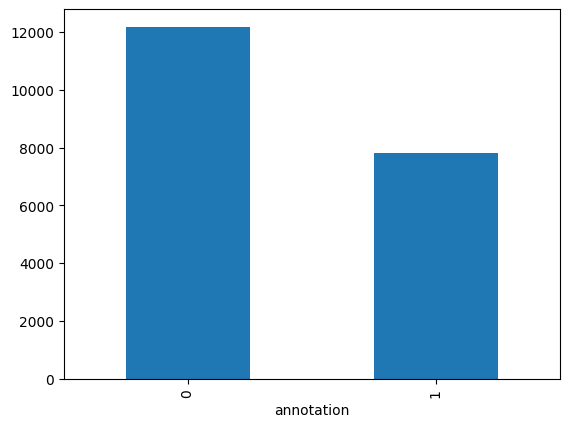

In [16]:
if "annotation" not in df.columns:
    print("Column 'annotation' not found! Check data source.")
else:
    df["annotation"].value_counts().sort_index().plot.bar()


In [17]:
print("PosiNon cyber trollingtive: ", df.annotation.value_counts()[0]/len(df.annotation)*100,"%")
print("Cybertrolling: ", df.annotation.value_counts()[1]/len(df.annotation)*100,"%")

PosiNon cyber trollingtive:  60.89195540222989 %
Cybertrolling:  39.10804459777012 %


In [18]:
nltk.download('stopwords')
stop = stopwords.words('english')

regex = re.compile('[%s]' % re.escape(string.punctuation))

def test_re(s):
    return regex.sub('', s)

df ['content_without_stopwords'] = df['content'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop)]))
df ['content_without_puncs'] = df['content_without_stopwords'].apply(lambda x: regex.sub('',x))
del df['content_without_stopwords']
del df['content']
df

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,annotation,content_without_puncs
0,1,Get fucking real dude
1,1,She dirty come crook Rengel Dems fucking corru...
2,1,fuck up I could day too Lets hour Ping later s...
3,1,Dude dont finish enclosing fucking showers I h...
4,1,WTF talking Men No men thats menage thats gay
...,...,...
19996,0,I dont But complaining going do
19997,0,Bahah yeah im totally gonna get pissed talking...
19998,0,hahahahaha im evil mwahahahahahahahahaha
19999,0,Whats something unique Ohio


In [19]:


# Download the punkt package if not already present
nltk.download('punkt_tab')

# Initialize the stemmer
porter_stemmer = PorterStemmer()

# Check if the required column exists
if 'content_without_puncs' not in df.columns:
    raise KeyError("Column 'content_without_puncs' not found in the DataFrame!")

tok_list = []
size = df.shape[0]

# Use .iloc to access rows by integer location (safer if your DataFrame index isn't sequential)
for i in range(size):
    word_data = df.iloc[i]['content_without_puncs']
    nltk_tokens = nltk.word_tokenize(word_data)
    # Use join for efficient string concatenation
    stemmed_text = ' '.join(porter_stemmer.stem(w) for w in nltk_tokens)
    tok_list.append(stemmed_text)

# Create a new column with the stemmed tokens and remove the old column
df['content_tokenize'] = tok_list
del df['content_without_puncs']

df


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,annotation,content_tokenize
0,1,get fuck real dude
1,1,she dirti come crook rengel dem fuck corrupt j...
2,1,fuck up i could day too let hour ping later sc...
3,1,dude dont finish enclos fuck shower i hate hal...
4,1,wtf talk men no men that menag that gay
...,...,...
19996,0,i dont but complain go do
19997,0,bahah yeah im total gon na get piss talk you m...
19998,0,hahahahaha im evil mwahahahahahahahahaha
19999,0,what someth uniqu ohio


In [20]:

noNums = []
for i in range(len(df)):
  noNums.append(''.join([i for i in df['content_tokenize'][i] if not i.isdigit()]))

df['content'] = noNums
df

,annotation,content_tokenize,content
0,1,get fuck real dude,get fuck real dude
1,1,she dirti come crook rengel dem fuck corrupt j...,she dirti come crook rengel dem fuck corrupt j...
2,1,fuck up i could day too let hour ping later sc...,fuck up i could day too let hour ping later sc...
3,1,dude dont finish enclos fuck shower i hate hal...,dude dont finish enclos fuck shower i hate hal...
4,1,wtf talk men no men that menag that gay,wtf talk men no men that menag that gay
...,...,...,...
19996,0,i dont but complain go do,i dont but complain go do
19997,0,bahah yeah im total gon na get piss talk you m...,bahah yeah im total gon na get piss talk you m...
19998,0,hahahahaha im evil mwahahahahahahahahaha,hahahahaha im evil mwahahahahahahahahaha
19999,0,what someth uniqu ohio,what someth uniqu ohio


In [21]:
tfIdfVectorizer=TfidfVectorizer(use_idf=True, sublinear_tf=True)
tfIdf = tfIdfVectorizer.fit_transform(df.content.tolist())

In [22]:
print(tfIdf)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 149064 stored elements and shape (20001, 14783)>
  Coords	Values
  (0, 4896)	0.3956616014132562
  (0, 4665)	0.3314842764826403
  (0, 10534)	0.6408032598619847
  (0, 3598)	0.5682792040556578
  (1, 4665)	0.12302268120056382
  (1, 11402)	0.24231137330135857
  (1, 3306)	0.294004579420996
  (1, 2453)	0.20014266836955738
  (1, 2791)	0.3609013757539863
  (1, 10686)	0.36956626902789813
  (1, 3127)	0.36956626902789813
  (1, 2649)	0.3478358132370042
  (1, 6881)	0.2707206754001475
  (1, 7868)	0.17712641457020445
  (1, 10707)	0.3380770158779807
  (1, 7670)	0.18997382467613527
  (1, 7497)	0.1421522208901913
  (2, 4665)	0.13750309629811014
  (2, 13605)	0.23740114979573212
  (2, 2665)	0.22315111540033278
  (2, 3004)	0.21159642031150855
  (2, 13110)	0.21898968900625004
  (2, 7434)	0.24199503289435126
  (2, 5956)	0.28144866948736874
  (2, 9784)	0.38298243181872793
  :	:
  (19997, 6367)	0.1440469139608353
  (19997, 13161)	0.22697440407580396


In [23]:
print(tfIdf.shape) # means total rows  20001 with 14783 features

(20001, 14783)


In [24]:
# Create a DataFrame for the third document (index 2) from the TF-IDF matrix
df2 = pd.DataFrame(tfIdf[2].T.todense(),
                   index=tfIdfVectorizer.get_feature_names_out(),
                   columns=["TF-IDF"])

# Sort the DataFrame by the TF-IDF values in descending order
df2 = df2.sort_values(by="TF-IDF", ascending=False)

# Print the top 10 features
print(df2.head(10))


         TF-IDF
sched  0.413066
ping   0.382982
later  0.306131
write  0.287619
book   0.285848
hour   0.281449
here   0.262648
let    0.241995
up     0.237401
could  0.223151


In [25]:
dfx = pd.DataFrame(tfIdf.toarray(), columns=tfIdfVectorizer.get_feature_names_out())
print(dfx)

        aa  aaaaaaaaaa  aaaaaanndgummi  aaaagh  aaaawwwww  aaand  \
0      0.0         0.0             0.0     0.0        0.0    0.0   
1      0.0         0.0             0.0     0.0        0.0    0.0   
2      0.0         0.0             0.0     0.0        0.0    0.0   
3      0.0         0.0             0.0     0.0        0.0    0.0   
4      0.0         0.0             0.0     0.0        0.0    0.0   
...    ...         ...             ...     ...        ...    ...   
19996  0.0         0.0             0.0     0.0        0.0    0.0   
19997  0.0         0.0             0.0     0.0        0.0    0.0   
19998  0.0         0.0             0.0     0.0        0.0    0.0   
19999  0.0         0.0             0.0     0.0        0.0    0.0   
20000  0.0         0.0             0.0     0.0        0.0    0.0   

       aaanyyywhoooooooo  aaargh  aaarrrg  aah  ...  zon  zone  zoo  zoom  \
0                    0.0     0.0      0.0  0.0  ...  0.0   0.0  0.0   0.0   
1                    0.0     

In [26]:

def display_scores(vectorizer, tfidf_result):
    scores = zip(vectorizer.get_feature_names(),
                 np.asarray(tfidf_result.sum(axis=0)).ravel())
    sorted_scores = sorted(scores, key=lambda x: x[1], reverse=True)
    i=0
    for item in sorted_scores:
        print ("{0:50} Score: {1}".format(item[0], item[1]))
        i = i+1
        if (i > 25):
          break

In [27]:
def display_scores(vectorizer, tfidf_result):
    # Get the feature names using the updated method
    feature_names = vectorizer.get_feature_names_out()
    # Sum TF-IDF scores across all documents (adjust as needed)
    scores = zip(feature_names, np.asarray(tfidf_result.sum(axis=0)).ravel())
    # Sort the features by their total score in descending order
    sorted_scores = sorted(scores, key=lambda x: x[1], reverse=True)

    # Print the top 25 sorted features and their scores
    for i, (word, score) in enumerate(sorted_scores):
        if i >= 25:
            break
        print(f"{word}: {score}")

# Now call the function
display_scores(tfIdfVectorizer, tfIdf)


hate: 534.510491846842
fuck: 504.1100776146435
damn: 482.6787946165052
suck: 407.9137415713778
ass: 338.4226995866781
that: 311.7839371040996
lol: 298.48455602425196
like: 288.23216991082853
you: 284.9003294941816
im: 270.77603080762424
it: 255.0521889380597
get: 253.7108377447594
what: 221.4485850838663
know: 211.80764994005472
would: 202.6961567855039
bitch: 193.2496795872102
ye: 182.56127327621266
love: 181.66343812796177
go: 180.66377673440317
haha: 179.71765224568028
think: 179.32380529969276
one: 174.35521066522898
do: 160.60613807319322
time: 160.19685177118623
gay: 159.8249445222399


In [28]:
X=tfIdf.toarray()
y = np.array(df.annotation.tolist())
#Spltting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(16000, 14783)
(16000,)
(4001, 14783)
(4001,)


In [29]:
#Training data biasness
unique_elements, counts_elements = np.unique(y_train, return_counts=True)
print(np.asarray((unique_elements, counts_elements)))

[[   0    1]
 [9750 6250]]


In [30]:
#Test Data
unique_elements, counts_elements = np.unique(y_test, return_counts=True)
print(np.asarray((unique_elements, counts_elements)))

[[   0    1]
 [2429 1572]]


In [31]:
#Random oversampling on training data
from imblearn.over_sampling import RandomOverSampler

oversample = RandomOverSampler(sampling_strategy='not majority')
X_over, y_over = oversample.fit_resample(X_train, y_train)

In [32]:
print(X_over.shape)
print(y_over.shape)

(19500, 14783)
(19500,)


In [33]:
unique_elements, counts_elements = np.unique(y_over, return_counts=True)
print(np.asarray((unique_elements, counts_elements)))

[[   0    1]
 [9750 9750]]


In [40]:
def getStatsFromModel(model):
  print(classification_report(y_test, y_pred))
  disp = plot_precision_recall_curve(model, X_test, y_test)
  disp.ax_.set_title('2-class Precision-Recall curve: '
                   'AP={0:0.2f}')

  logit_roc_auc = roc_auc_score(y_test, model.predict(X_test))
  fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test)[:,1])
  plt.figure()
  plt.plot(fpr, tpr, label='(area = %0.2f)' % logit_roc_auc)
  plt.plot([0, 1], [0, 1],'r--')
  plt.xlim([0.0, 1.0])
  plt.ylim([0.0, 1.05])
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('Receiver operating characteristic')
  plt.legend(loc="lower right")
  plt.savefig('Log_ROC')
  plt.show()

Score: 0.6160959760059985
Confusion Matrix:
 [[ 924 1505]
 [  31 1541]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.38      0.55      2429
           1       0.51      0.98      0.67      1572

    accuracy                           0.62      4001
   macro avg       0.74      0.68      0.61      4001
weighted avg       0.79      0.62      0.59      4001



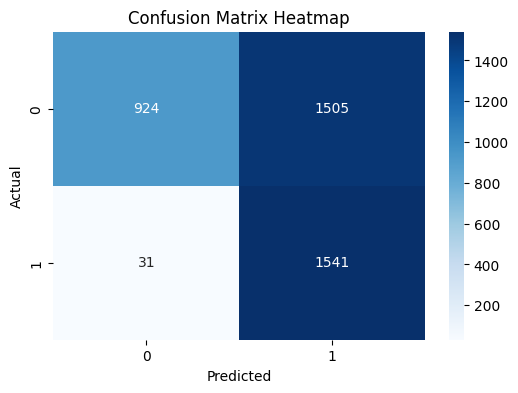

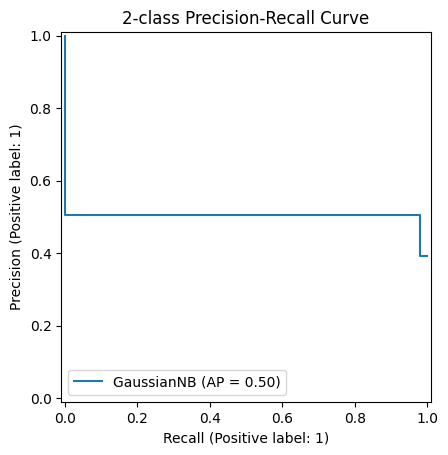

In [60]:
# Train the model
gnb = GaussianNB()
gnb_model = gnb.fit(X_over, y_over)
y_pred = gnb_model.predict(X_test)

# Print accuracy score and confusion matrix
print("Score:", gnb_model.score(X_test, y_test))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Function to display classification report, heatmap, and PR curve
def getStatsFromModel(model, X_test, y_test, y_pred):
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion matrix heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix Heatmap')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Precision-recall curve
    disp = PrecisionRecallDisplay.from_estimator(model, X_test, y_test)
    disp.ax_.set_title('2-class Precision-Recall Curve')
    plt.show()

# Call the function
getStatsFromModel(gnb_model, X_test, y_test, y_pred)

Accuracy: 0.802049487628093
Confusion Matrix:
 [[1898  531]
 [ 261 1311]]
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      2429
           1       0.71      0.83      0.77      1572

    accuracy                           0.80      4001
   macro avg       0.80      0.81      0.80      4001
weighted avg       0.81      0.80      0.80      4001



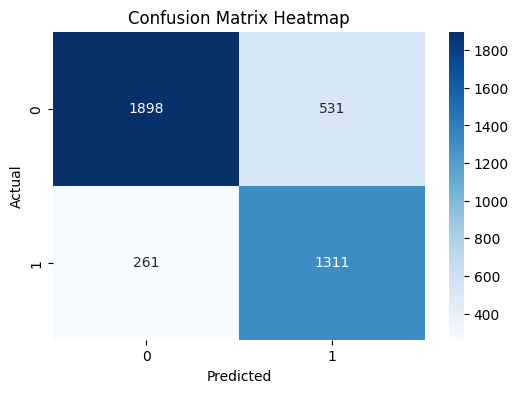

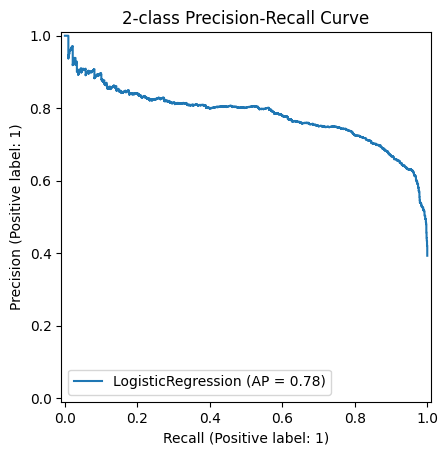

In [41]:

lgr = LogisticRegression()
lgr.fit(X_over, y_over)
y_pred = lgr.predict(X_test)

# Print accuracy and confusion matrix
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Define a function to show metrics and plots
def getStatsFromModel(model, X_test, y_test, y_pred):
    # Print classification report
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot confusion matrix heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix Heatmap')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Plot precision-recall curve
    disp = PrecisionRecallDisplay.from_estimator(model, X_test, y_test)
    disp.ax_.set_title('2-class Precision-Recall Curve')
    plt.show()

# Call the function
getStatsFromModel(lgr, X_test, y_test, y_pred)

Accuracy:  0.8505373656585854
Confusion Matrix: 
 [[1886  543]
 [  55 1517]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.78      0.86      2429
           1       0.74      0.97      0.84      1572

    accuracy                           0.85      4001
   macro avg       0.85      0.87      0.85      4001
weighted avg       0.88      0.85      0.85      4001



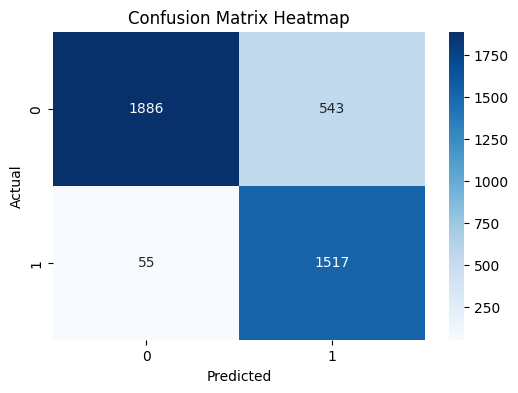

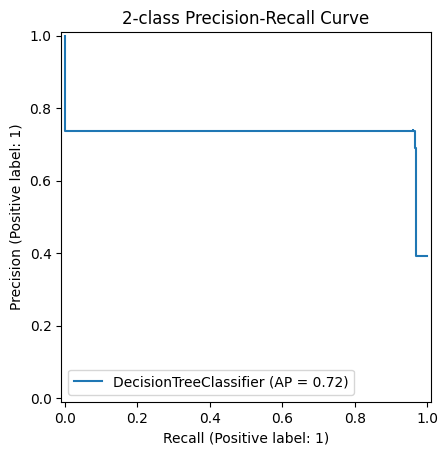

In [42]:
# Train the model
dtc = DecisionTreeClassifier()
dtc.fit(X_over, y_over)
y_pred = dtc.predict(X_test)

# Print accuracy and confusion matrix
print("Accuracy: ", metrics.accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: \n", cm)

# Define the function to show metrics and plots
def getStatsFromModel(model, X_test, y_test, y_pred):
    # Print classification report
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot confusion matrix heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix Heatmap')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Plot the precision-recall curve
    disp = PrecisionRecallDisplay.from_estimator(model, X_test, y_test)
    disp.ax_.set_title('2-class Precision-Recall Curve')
    plt.show()

# Call the function
getStatsFromModel(dtc, X_test, y_test, y_pred)

Accuracy:  0.69407648087978
Confusion Matrix: 
 [[1990  439]
 [ 785  787]]
Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.82      0.76      2429
           1       0.64      0.50      0.56      1572

    accuracy                           0.69      4001
   macro avg       0.68      0.66      0.66      4001
weighted avg       0.69      0.69      0.69      4001



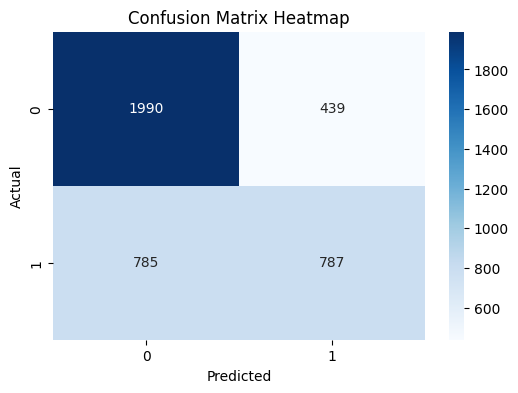

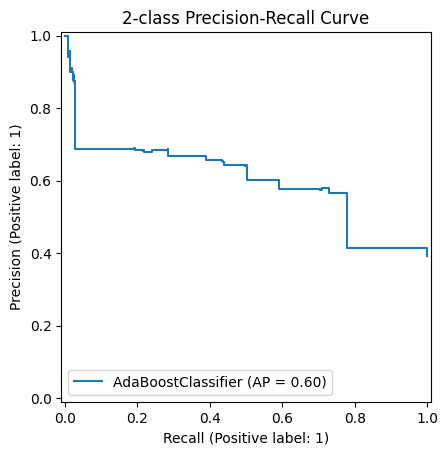

In [55]:
# Train the model
# Train the model
abc = AdaBoostClassifier()
abc.fit(X_over, y_over)
y_pred = abc.predict(X_test)

# Print accuracy and confusion matrix
print("Accuracy: ", metrics.accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: \n", cm)

# Define the function to show metrics and plots
def getStatsFromModel(model, X_test, y_test, y_pred):
      # Print classification report
      print("Classification Report:")
      print(classification_report(y_test, y_pred))

      # Plot confusion matrix heatmap
      plt.figure(figsize=(6, 4))
      sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
      plt.title('Confusion Matrix Heatmap')
      plt.xlabel('Predicted')
      plt.ylabel('Actual')
      plt.show()

      # Plot the precision-recall curve
      disp = PrecisionRecallDisplay.from_estimator(model, X_test, y_test)
      disp.ax_.set_title('2-class Precision-Recall Curve')
      plt.show()

# Call the function
getStatsFromModel(abc, X_test, y_test, y_pred)


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:  3.6min
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:  7.3min finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.6s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.3s finished
[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.6s


Score: 0.9150212446888278
Confusion Matrix: 
 [[2166  263]
 [  77 1495]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.89      0.93      2429
           1       0.85      0.95      0.90      1572

    accuracy                           0.92      4001
   macro avg       0.91      0.92      0.91      4001
weighted avg       0.92      0.92      0.92      4001



[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.3s finished


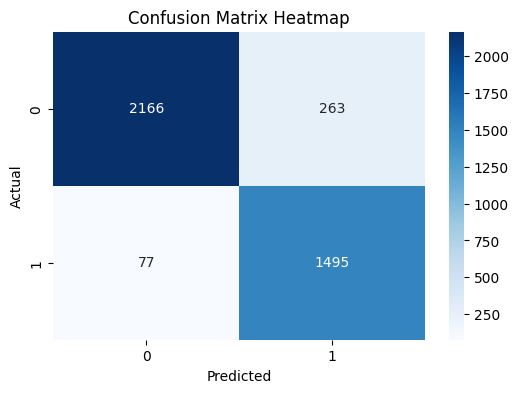

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.6s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    1.3s finished


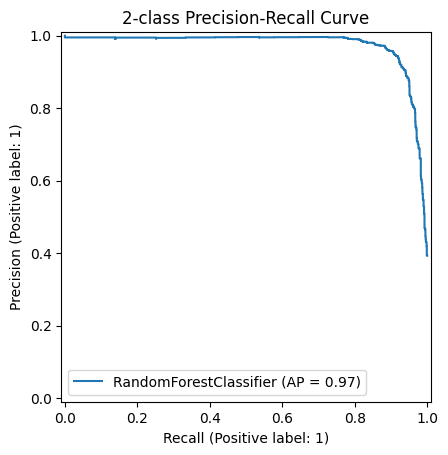

In [59]:
# Initialize and fit the RandomForestClassifier model
rfc = RandomForestClassifier(verbose=True)  # uses randomized decision trees
rfc_model = rfc.fit(X_over, y_over)

# Predict on the test set
y_pred = rfc_model.predict(X_test)

# Print score and confusion matrix
print("Score:", rfc_model.score(X_test, y_test))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: \n", cm)

# Define helper function to show metrics and plots
def getStatsFromModel(model, X_test, y_test, y_pred):
    # Print classification report
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Plot confusion matrix heatmap
    plt.figure(figsize=(6, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion Matrix Heatmap')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    # Plot the precision-recall curve
    disp = PrecisionRecallDisplay.from_estimator(model, X_test, y_test)
    disp.ax_.set_title('2-class Precision-Recall Curve')
    plt.show()

# Call the function
getStatsFromModel(rfc_model, X_test, y_test, y_pred)

In [ ]:
import joblib

# Save your trained RandomForestClassifier
joblib.dump(rfc_model, '/content/saved/model_random_forest.joblib')


In [ ]:
# During training in Colab
import joblib
joblib.dump(tfIdfVectorizer, 'tfidf_vectorizer.joblib')
